# Guide pour l'Appel à une API Hugging Face pour la Segmentation d'Images

Bienvenue ! Ce notebook a pour but de vous guider pas à pas dans l'utilisation de l'API d'inférence de Hugging Face pour effectuer de la segmentation d'images. La segmentation d'images consiste à attribuer une étiquette (comme "cheveux", "vêtement", "arrière-plan") à chaque pixel d'une image.

Nous allons :
1. Comprendre ce qu'est une API et comment s'y connecter.
2. Envoyer une image à un modèle de segmentation hébergé sur Hugging Face.
3. Récupérer et interpréter les résultats.
4. Visualiser les masques de segmentation.
5. Étendre cela pour traiter plusieurs images.

## 1. Configuration Initiale et Importations

Commençons par importer les bibliothèques Python nécessaires. Nous aurons besoin de :
- `os` pour interagir avec le système de fichiers (lister les images).
- `requests` pour effectuer des requêtes HTTP vers l'API.
- `PIL (Pillow)` pour manipuler les images.
- `matplotlib.pyplot` pour afficher les images et les masques.
- `numpy` pour la manipulation des tableaux (les images sont des tableaux de pixels).
- `tqdm.notebook` pour afficher une barre de progression (utile pour plusieurs images).
- `base64` et `io` pour décoder les masques renvoyés par l'API.

In [25]:
import os
import requests
from PIL import Image
import re

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd

import numpy as np
from tqdm import tqdm
import base64
import time

from dotenv import load_dotenv
import os
import io


### Variables de Configuration

Nous devons définir quelques variables :
- `image_dir`: Le chemin vers le dossier contenant vos images. **Assurez-vous de modifier ce chemin si nécessaire.**
- `max_images`: Le nombre maximum d'images à traiter (pour ne pas surcharger l'API ou attendre trop longtemps).
- `api_token`: Votre jeton d'API Hugging Face. **IMPORTANT : Gardez ce jeton secret !**

**Comment obtenir un token API Hugging Face ?**
1. Créez un compte sur [huggingface.co](https://huggingface.co/).
2. Allez dans votre profil -> Settings -> Access Tokens.
3. Créez un nouveau token (par exemple, avec le rôle "read").
4. Copiez ce token ici.

In [16]:
# TODO: Modifiez ces valeurs selon votre configuration
image_dir = r"..\data\IMG"  # Exemple : si vous êtes sur Colab et avez uploadé un dossier
max_images = 5 # Commençons avec peu d'images
Masque_ref_dir = r"..\data\Mask"

# Charge automatiquement le fichier .env (à la racine ou dans le dossier courant)
load_dotenv()

# Récupère le token
token = os.getenv("TOKEN_HUG")

# Créons le dossier d'images s'il n'existe pas (pour l'exemple)
if not os.path.exists(image_dir):
    os.makedirs(image_dir)
    print(f"Dossier '{image_dir}' créé. Veuillez y ajouter des images .jpg ou .png.")
else:
    print(f"Dossier '{image_dir}' existant.")

if not os.path.exists(Masque_ref_dir):
    os.makedirs(Masque_ref_dir)
    print(f"Dossier '{Masque_ref_dir}' créé. Veuillez y ajouter les masques de référence.")
else:
    print(f"Dossier '{Masque_ref_dir}' existant.")

if token == "":
    print("\nATTENTION : Vous devez remplacer 'VOTRE_TOKEN' par votre token API personnel.")
else:
    print ("Token_ok")



Dossier '..\data\IMG' existant.
Dossier '..\data\Mask' existant.
Token_ok


## 2. Comprendre l'API d'Inférence Hugging Face

L'API d'inférence permet d'utiliser des modèles hébergés sur Hugging Face sans avoir à les télécharger ou à gérer l'infrastructure.

- **Modèle utilisé** : Nous allons utiliser le modèle `sayeed99/segformer_b3_clothes`, spécialisé dans la segmentation de vêtements et de parties du corps.
- **URL de l'API** : L'URL pour un modèle est généralement `https://api-inference.huggingface.co/models/NOM_DU_MODELE`.
- **Headers (En-têtes)** : Pour s'authentifier et spécifier le type de contenu, nous envoyons des en-têtes avec notre requête.
    - `Authorization`: Contient notre token API (précédé de `Bearer `).
    - `Content-Type`: Indique que nous envoyons une image au format JPEG (ou PNG selon le cas).

In [21]:
#API_URL = "https://api-inference.huggingface.co/models/yeed99/segformer_b3_clothes" # Remplacez ... par le bon endpoint.
API_URL = "https://router.huggingface.co/hf-inference/models/sayeed99/segformer_b3_clothes"
headers = {
    "Authorization": f"Bearer {token}"
    # Le "Content-Type" sera ajouté dynamiquement lors de l'envoi de l'image
}

### Fonction de tri naturel ---
def tri_naturel(path):
    nom_fichier = os.path.basename(path)
    return [int(s) if s.isdigit() else s for s in re.split(r'(\d+)', nom_fichier)]

### Récupération et tri des fichiers images ---
# Lister les chemins des images à traiter
# Assurez-vous d'avoir des images dans le dossier 'image_dir'!
# A vous de jouer !

# je crée une liste de chemlin d'image en m'assurant que ce sont bien des images

toutes_les_images = [
    os.path.join(image_dir, f)
    for f in os.listdir(image_dir)
    if os.path.isfile(os.path.join(image_dir, f))
    and f.lower().endswith((".png", ".jpg", ".jpeg", ".gif"))
]

# Tri naturel (ex: image_2 avant image_10)
toutes_les_images = sorted(toutes_les_images, key=tri_naturel)

# On garde seulement le nombre demandé
image_paths = toutes_les_images[:max_images]

if not image_paths:
    print(f"Aucune image trouvée dans '{image_dir}'. Veuillez y ajouter des images.")
else:
    print(f"{len(image_paths)} image(s) à traiter : {image_paths}")
    
tous_les_masques = [
    os.path.join(Masque_ref_dir, f) # pour avoir un chemin sans erreur
    for f in os.listdir(Masque_ref_dir) # pour chaque elements contenu dans mon repertoire
    if os.path.isfile(os.path.join(Masque_ref_dir, f)) 
    and f.lower().endswith((".png", ".jpg", ".jpeg", ".gif")) # si c'est un fichier et que c'est une image
]
# Tri naturel (ex: image_2 avant image_10)
tous_les_masques = sorted(tous_les_masques, key=tri_naturel)

Masque_ref_paths=tous_les_masques[:max_images] # le maximum demandé

if not Masque_ref_paths:
    print(f"Aucun masque de reference trouvé dans '{Masque_ref_dir}'. Veuillez en ajouter.")
else:
    print(f"{len(Masque_ref_paths)} image(s) à traiter : {Masque_ref_paths}")


5 image(s) à traiter : ['..\\data\\IMG\\image_0.png', '..\\data\\IMG\\image_1.png', '..\\data\\IMG\\image_2.png', '..\\data\\IMG\\image_3.png', '..\\data\\IMG\\image_4.png']
5 image(s) à traiter : ['..\\data\\Mask\\mask_0.png', '..\\data\\Mask\\mask_1.png', '..\\data\\Mask\\mask_2.png', '..\\data\\Mask\\mask_3.png', '..\\data\\Mask\\mask_4.png']


## 3. Fonctions Utilitaires pour le Traitement des Masques

Le modèle que nous utilisons (`sayeed99/segformer_b3_clothes`) renvoie des masques pour différentes classes (cheveux, chapeau, etc.). Ces masques sont encodés en base64. Les fonctions ci-dessous sont fournies pour vous aider à :
1.  `CLASS_MAPPING`: Un dictionnaire qui associe les noms de classes (ex: "Hat") à des identifiants numériques.
2.  `get_image_dimensions`: Récupérer les dimensions d'une image.
3.  `decode_base64_mask`: Décoder un masque de base64 en une image (tableau NumPy) et le redimensionner.
4.  `create_masks`: Combiner les masques de toutes les classes détectées en un seul masque de segmentation final, où chaque pixel a la valeur de l'ID de sa classe.

**Cette partie est donnée car elle est spécifique au format de sortie de ce modèle et un peu complexe pour une première approche.** Lisez-la pour comprendre son rôle, mais ne vous attardez pas sur les détails d'implémentation pour l'instant.

In [18]:
CLASS_MAPPING = {
    "Background": 0,
    "Hat": 1,
    "Hair": 2,
    "Sunglasses": 3,
    "Upper-clothes": 4,
    "Skirt": 5,
    "Pants": 6,
    "Dress": 7,
    "Belt": 8,
    "Left-shoe": 9,
    "Right-shoe": 10,
    "Face": 11,
    "Left-leg": 12,
    "Right-leg": 13,
    "Left-arm": 14,
    "Right-arm": 15,
    "Bag": 16,
    "Scarf": 17
}

CLASS_NAMES = {
    1: "Hat",
    2: "Hair",
    3: "Sunglasses",
    4: "Upper-clothes",
    5: "Skirt",
    6: "Pants",
    7: "Dress",
    8: "Belt",
    9: "Left-shoe",
    10: "Right-shoe",
    11: "Face",
    12: "Left-leg",
    13: "Right-leg",
    14: "Left-arm",
    15: "Right-arm",
    16: "Bag",
    17: "Scarf"
}

CLASS_COLORS = {
    0: (0, 0, 0, 0),         # Background transparent
    1: (0, 255, 255, 120),   # Jaune - Hat
    2: (0, 165, 255, 120),   # Orange - Hair
    3: (255, 0, 255, 120),   # Magenta - Sunglasses
    4: (0, 0, 255, 120),     # Rouge - Upper-clothes
    5: (255, 255, 0, 120),   # Cyan - Skirt
    6: (0, 255, 0, 120),     # Vert - Pants
    7: (255, 0, 0, 120),     # Bleu - Dress
    8: (128, 0, 128, 120),   # Violet - Belt
    9: (0, 255, 255, 120),   # Jaune - Left-shoe
    10: (255, 140, 0, 120),  # Orange foncé - Right-shoe
    11: (222, 184, 135, 120),   # Face - beige clair
    12: (210, 180, 140, 120),   # Left-leg - beige moyen
    13: (205, 170, 125, 120),   # Right-leg - beige chaud
    14: (218, 165, 105, 120),   # Left-arm - beige doré
    15: (244, 164, 96, 120),    # Right-arm - beige cuivré
    16: (0, 128, 255, 120),  # Bleu clair - Bag
    17: (255, 20, 147, 120)  # Rose - Scarf
}
def get_image_dimensions(img_path):
    """
    Get the dimensions of an image.

    Args:
        img_path (str): Path to the image.

    Returns:
        tuple: (width, height) of the image.
    """
    original_image = Image.open(img_path)
    return original_image.size

def decode_base64_mask(base64_string, width, height):
    """
    Decode a base64-encoded mask into a NumPy array.

    Args:
        base64_string (str): Base64-encoded mask.
        width (int): Target width.
        height (int): Target height.

    Returns:
        np.ndarray: Single-channel mask array.
    """
    mask_data = base64.b64decode(base64_string)
    mask_image = Image.open(io.BytesIO(mask_data))
    mask_array = np.array(mask_image)

    if len(mask_array.shape) == 3:
        mask_array = mask_array[:, :, 0]  # Take first channel if RGB
    mask_image = Image.fromarray(mask_array).resize((width, height), Image.NEAREST)
    return np.array(mask_image)

def create_masks(results, width, height):
    """
    Combine multiple class masks into a single segmentation mask.

    Args:
        results (list): List of dictionaries with 'label' and 'mask' keys.
        width (int): Target width.
        height (int): Target height.

    Returns:
        np.ndarray: Combined segmentation mask with class indices.
    """
    combined_mask = np.zeros((height, width), dtype=np.uint8)  # Initialize with Background (0)

    # Process non-Background masks first
    for result in results:
        label = result['label']
        class_id = CLASS_MAPPING.get(label, 0)
        if class_id == 0:  # Skip Background
            continue
        mask_array = decode_base64_mask(result['mask'], width, height)
        combined_mask[mask_array > 0] = class_id

    # Process Background last to ensure it doesn't overwrite other classes unnecessarily
    # (Though the model usually provides non-overlapping masks for distinct classes other than background)
    for result in results:
        if result['label'] == 'Background':
            mask_array = decode_base64_mask(result['mask'], width, height)
            # Apply background only where no other class has been assigned yet
            # This logic might need adjustment based on how the model defines 'Background'
            # For this model, it seems safer to just let non-background overwrite it first.
            # A simple application like this should be fine: if Background mask says pixel is BG, set it to 0.
            # However, a more robust way might be to only set to background if combined_mask is still 0 (initial value)
            combined_mask[mask_array > 0] = 0 # Class ID for Background is 0
    
    return combined_mask
    
#changement couleur
def Colore_Mask (
        Masque_initial,
        hauteur,
        largeur
        ) :
    
    Masque_retour = np.zeros((hauteur, largeur, 4), dtype=np.uint8)
    
    for class_id, color in CLASS_COLORS.items():
        Masque_retour[Masque_initial == class_id] = color
    
    return Masque_retour

def alignement_masque_prediction(masque_reference: np.ndarray, masque_prediction: np.ndarray):

    h_pred, w_pred = masque_prediction.shape[:2]
    if masque_reference.shape[:2] != (h_pred, w_pred):
        gt_resized = np.array(
            Image.fromarray(masque_reference).resize((w_pred, h_pred), resample=Image.NEAREST)
        )
        return gt_resized
    return masque_reference

# fonctions de calcul des IoU et dices
def iou_multiclass (
    Masque_pred: np.ndarray,
    Masque_ref: np.ndarray,
    num_classes_vetement: int = len(CLASS_COLORS), #le nombre de classes de vetements =17 toutes
    average: str = "all",   # "all"=toutes les classes de vetements ou "present"= celles presentes sur le masque uniquement
    eps: float = 1e-9 #eviter les divisions par 0
    ) :
 
    assert Masque_pred.shape == Masque_ref.shape, "les 2 masques doivent etre de la même taille."
    assert average in {"all", "present"}, "average doit être 'all' ou 'present'"
    
    # remplissage à 0 
    ious = np.zeros(num_classes_vetement , dtype=np.float64)
    present_mask = np.zeros(num_classes_vetement, dtype=bool)  # classes présentes dans le GT

    #pour chaque classes de vetements demandé
    for Vetement in range(1,num_classes_vetement):

        pred_vetement = (Masque_pred == Vetement)
        ref_vetement   = (Masque_ref == Vetement)

        #Calcul
        intersection = np.logical_and(pred_vetement, ref_vetement).sum()
        union = np.logical_or(pred_vetement, ref_vetement).sum()
        
        #presence du vetement ou pas
        if ref_vetement.any():
            present_mask[Vetement] = True

        #ajout iou du vetement concerné
        ious[Vetement] = intersection / (union + eps)

    if average == "present":
        #uniquement les vetements presents pour la moyenne
        denominateur = max(present_mask[1:].sum(), 1) #eviter division par 0
        mean_iou = float(ious[1:][present_mask[1:]].sum() / denominateur)
    else:
        #tout les masques meme ceux absent
        mean_iou = float(ious[1:].mean())

    code_classe = np.arange(1, num_classes_vetement)
    table_Ious= np.column_stack((code_classe, ious[1:]))

    return table_Ious, mean_iou


def dice_multiclass(
    Masque_pred: np.ndarray,
    Masque_ref: np.ndarray,
    num_classes_vetement: int = len(CLASS_COLORS),
    average: str = "all",
    eps: float = 1e-9
):

    assert Masque_pred.shape == Masque_ref.shape, "les 2 masques doivent être de la même taille."
    assert average in {"all", "present"}, "average doit être 'all' ou 'present'"

    Masque_pred = Masque_pred.astype(np.int32, copy=False)
    Masque_ref   = Masque_ref.astype(np.int32, copy=False)

    dices = np.zeros(num_classes_vetement, dtype=np.float64)
    present_mask = np.zeros(num_classes_vetement, dtype=bool)

    for vetement in range(1, num_classes_vetement):
        pred_vetement = (Masque_pred == vetement)
        ref_vetement   = (Masque_ref == vetement)

        inter = np.logical_and(pred_vetement, ref_vetement).sum()
        total = pred_vetement.sum() + ref_vetement.sum()

        if ref_vetement.any():
            present_mask[vetement] = True

        dices[vetement] = (2.0 * inter) / (total + eps)

    if average == "present":
        denom = max(present_mask[1:].sum(), 1)
        mean_dice = float(dices[1:][present_mask[1:]].sum() / denom)
    else:
        mean_dice = float(dices[1:].mean())

    code_classe = np.arange(1, num_classes_vetement)
    table_Dices= np.column_stack((code_classe, dices[1:]))

    return table_Dices, mean_dice

# fonctions d'exploitation de resultat

def moyenne_total(Tableau): #moyenne meme si iou=0
    return float(np.mean(Tableau)) if len(Tableau) else 0.0 #tout sur la meme ligne

def moyenne_presente(Tableau, support): #moyenne si presence dans le masque de reference
    m = (support> 0)
    return float(np.mean(Tableau[m])) if m.any() else 0.0 #tout sur la meme ligne

def moyenne_ponderee(Tableau, support): #moyenne ponderee en fonction de la presence sur le masque de reference
    m = (support > 0)
    if not m.any(): 
        return 0.0
    w = support[m].astype(float)
    w = w / (w.sum() + 1e-9)
    return float((Tableau[m] * w).sum())




## 4. Segmentation d'une Seule Image

Avant de traiter toutes les images, concentrons-nous sur une seule pour bien comprendre le processus.

Étapes :
1.  Choisir une image.
2.  Ouvrir l'image en mode binaire (`"rb"`) et lire son contenu (`data`).
3.  Déterminer le `Content-Type` (par exemple, `"image/jpeg"` ou `"image/png"`).
4.  Envoyer la requête POST à l'API avec `requests.post()` en passant l'URL, les headers et les données.
5.  Vérifier le code de statut de la réponse. Une erreur sera levée si le code n'est pas 2xx (succès) grâce à `response.raise_for_status()`.
6.  Convertir la réponse JSON en un dictionnaire Python avec `response.json()`.
7.  Utiliser nos fonctions `get_image_dimensions` et `create_masks` pour obtenir le masque final.
8.  Afficher l'image originale et le masque segmenté.

In [19]:
if image_paths:
    single_image_path = image_paths[0] # Prenons la première image de notre liste
    print(f"Traitement de l'image : {single_image_path}")

    try:
        # je charge un objet image a partir du chemin pour connaitre son content-type
        #Ancienne 
        extension_fichier = (os.path.splitext(image_paths[0])[-1].lower())
        
        #je construit le content-type à partir du type de l'image, le tout au format attendu par l'api
        content_type = {".jpg" : "image/jpeg", 
                ".jpeg" : "image/jpeg",
                ".png" : "image/png",
                ".bmp" : "image/bmp",
                ".gif" : "image/gif"}.get(extension_fichier,"application/octet-stream")

        print("Format détecté :", extension_fichier, "| Content-Type :", content_type)
        
        # j'envoie l'information à ma variable headers
        headers["Content-Type"] = content_type
        
        # Lire l'image en binaire
        with open(image_paths[0] , "rb") as image_traitee : 
            # lire le contenu en data
            image_data = image_traitee.read()
        
        with open(Masque_ref_paths[0] , "rb") as masque_ref_traite : 
            # lire le contenu en data
            masque_ref_image = Image.open(Masque_ref_paths[0])

        masque_ref_final = np.array(masque_ref_image)

        # Maintenant, utilisé l'API huggingface
        # ainsi que les fonctions données plus haut pour ségmenter vos images.

        #utilisation de l'API
        Reponse_API = requests.post(API_URL, data=image_data, headers={**headers,"Content-Type":content_type})
        
        #Reponse sous forme dun dictionnaire python
        Reponse = Reponse_API.json()
        
        #Taille de l'image en utilisant la methode
        width_Image, height_Image = get_image_dimensions(image_paths[0])

        #je crée le masque avec la methode et je la convertie en image
        Masque_prediction_final = create_masks (Reponse, width_Image,height_Image)
        masque_ref_final = alignement_masque_prediction (masque_ref_final, Masque_prediction_final)

        ious_par_vetement, Moyenne_iou = iou_multiclass(Masque_prediction_final, masque_ref_final, average="present")
        dices_par_vetement, Moyenne_dice = dice_multiclass (Masque_prediction_final, masque_ref_final, average="present")
        
        Masque_couleur = Colore_Mask (Masque_prediction_final, height_Image, width_Image)

        Masque_Image = Image.fromarray(Masque_couleur)
        
        #affichage de l'image et son masque
        #Masque_Image.show()
        
    except Exception as e:
        print(f"Une erreur est survenue : {e}")
else:
    print("Aucune image à traiter. Vérifiez la configuration de 'image_dir' et 'max_images'.")

Traitement de l'image : ..\data\IMG\image_0.png
Format détecté : .png | Content-Type : image/png


## 5. Segmentation de Plusieurs Images (Batch)

Maintenant que nous savons comment traiter une image, nous pouvons créer une fonction pour en traiter plusieurs.
Cette fonction va boucler sur la liste `image_paths` et appliquer la logique de segmentation à chaque image.
Nous utiliserons `tqdm` pour avoir une barre de progression.

In [27]:
def segment_images_batch(list_of_image_paths, Masque_ref_paths, mode_segmentation = "RGBA"):
    
    #le tableau de retour 
    batch_segmentations = []
    Tableau_de_resultats = []
    dataframe_resultats = []

    try :
        # Args:
        #         list_of_image_paths (list): Liste des chemins vers les images.
        for image_path, mask_path in tqdm(zip(list_of_image_paths, Masque_ref_paths),
                                        desc="Traitement des images en cours",
                                        total = min(len(list_of_image_paths), len(Masque_ref_paths)),
                                        ) :
            try : 
                # je charge un objet image a partir du chemin pour connaitre son content-type 
                extension_fichier = (os.path.splitext(image_path)[-1].lower())
                image_nom = os.path.basename(image_path)

                #je construit le content-type à partir du type de l'image, le tout au format attendu par l'api
                content_type = {".jpg" : "image/jpeg", 
                        ".jpeg" : "image/jpeg",
                        ".png" : "image/png",
                        ".bmp" : "image/bmp",
                        ".gif" : "image/gif"}.get(extension_fichier,"application/octet-stream")
            
                with open(image_path, "rb") as image_traitee : 
                    # lire le contenu en data
                    image_data = image_traitee.read()
                
                # with open(mask_path , "rb") as masque_ref_traite : 
                #     # lire le contenu en data
                #     masque_ref_image = Image.open(masque_ref_traite)

                masque_ref_image = Image.open(mask_path).convert("L")
                masque_ref_final = np.array(masque_ref_image, dtype=np.int32)
                        
                #Segmente une liste d'images en utilisant l'API Hugging Face.
                Reponse_API = requests.post(API_URL, data=image_data, headers={**headers, "Content-Type" : content_type}, timeout=60)
               
                # N'oubliez pas de mettre une pause entre chaque appel API !
                time.sleep(1)
            
                #renvoie en realité none si forme est 2xx soit sans erreur
                if 200 <= Reponse_API.status_code < 300 : #ou Reponse_API.ok
                    #Reponse sous forme dun dictionnaire python
                    Reponse = Reponse_API.json()
                    #Taille de l'image en utilisant la methode
               
                    width_Image, height_Image = get_image_dimensions(image_path)

                    #je crée le masque avec la methode et je la convertie en image
                    masque_pred_final = create_masks (Reponse, width_Image, height_Image)
                    
                    #les 2 masques doivent avoir la meme taille
                    masque_ref_final = alignement_masque_prediction (masque_ref_final, masque_pred_final)

                    #calcul IOU/ class et moyenne 
                    ious_par_vetement, Moyenne_iou = iou_multiclass(masque_pred_final, masque_ref_final, average="present")
                   
                    #calcul DICES/ class et moyenne 
                    dices_par_vetement, Moyenne_dice = dice_multiclass (masque_pred_final, masque_ref_final, average="present")
                   
                    for c in range(1, len(CLASS_COLORS)):
                        
                        support = int((masque_ref_final == c).sum())
                        
                        Tableau_de_resultats.append([
                            image_nom,            # image_id
                            c,                   # class_id
                            support,             # support_GT
                            float(ious_par_vetement[c-1][1]),   # IoU de cette classe
                            float(dices_par_vetement[c-1][1])   # Dice de cette classe
                            ])

                    #J'ai rajouté la possibilité de convertir l'image en couleur au lieu du gris
                    if mode_segmentation.upper() == "RGBA" :
                        #Je remplace les gris pour la couleur choisie
                        masque_pred_final = Colore_Mask (masque_pred_final,height_Image,width_Image)

                    Masque_Image = Image.fromarray(masque_pred_final)
                        
                    batch_segmentations.append(Masque_Image)    

                else :
                    print(f"Erreur {Reponse_API.status_code} : Image non traitée: {image_path} ") #apprentissage fstring
                    batch_segmentations.append(None) 
                    continue
                
            #Je recupere l'erreur de la classe exception dans e
            except Exception as e: 
                print(f"Erreur : Image non traitée: {image_path} → {e}")
                batch_segmentations.append(None)
                continue

        dataframe_resultats = pd.DataFrame(
            Tableau_de_resultats,
            columns=["Nom_Image", "Classe_vetement", "Support", "IoU", "Dice"]
            )
           
        return batch_segmentations,  dataframe_resultats
    
    # Returns:
    #     list: Liste des masques de segmentation (tableaux NumPy).
    #           Contient None si une image n'a pas pu être traitée.
    

    except Exception as e: 
        print(f"Erreur : Fichier  → {e}")
        return batch_segmentations, dataframe_resultats

# Appeler la fonction pour segmenter les images listées dans image_paths
if image_paths:
    print(f"\nTraitement de {len(image_paths)} image(s) en batch...")
    batch_seg_results , Resultats = segment_images_batch(image_paths, Masque_ref_paths, mode_segmentation="RGBA") ## ici gray ou RGBA (par defaut)
    print("Traitement en batch terminé.")
else:
    batch_seg_results = []
    Resultats = []
    
    print("Aucune image à traiter en batch.")



Traitement de 5 image(s) en batch...


Traitement des images en cours: 100%|██████████| 5/5 [00:11<00:00,  2.39s/it]

Traitement en batch terminé.


## 6. Affichage des Résultats en Batch

Nous allons maintenant créer une fonction pour afficher les images originales et leurs segmentations correspondantes côte à côte, dans une grille.

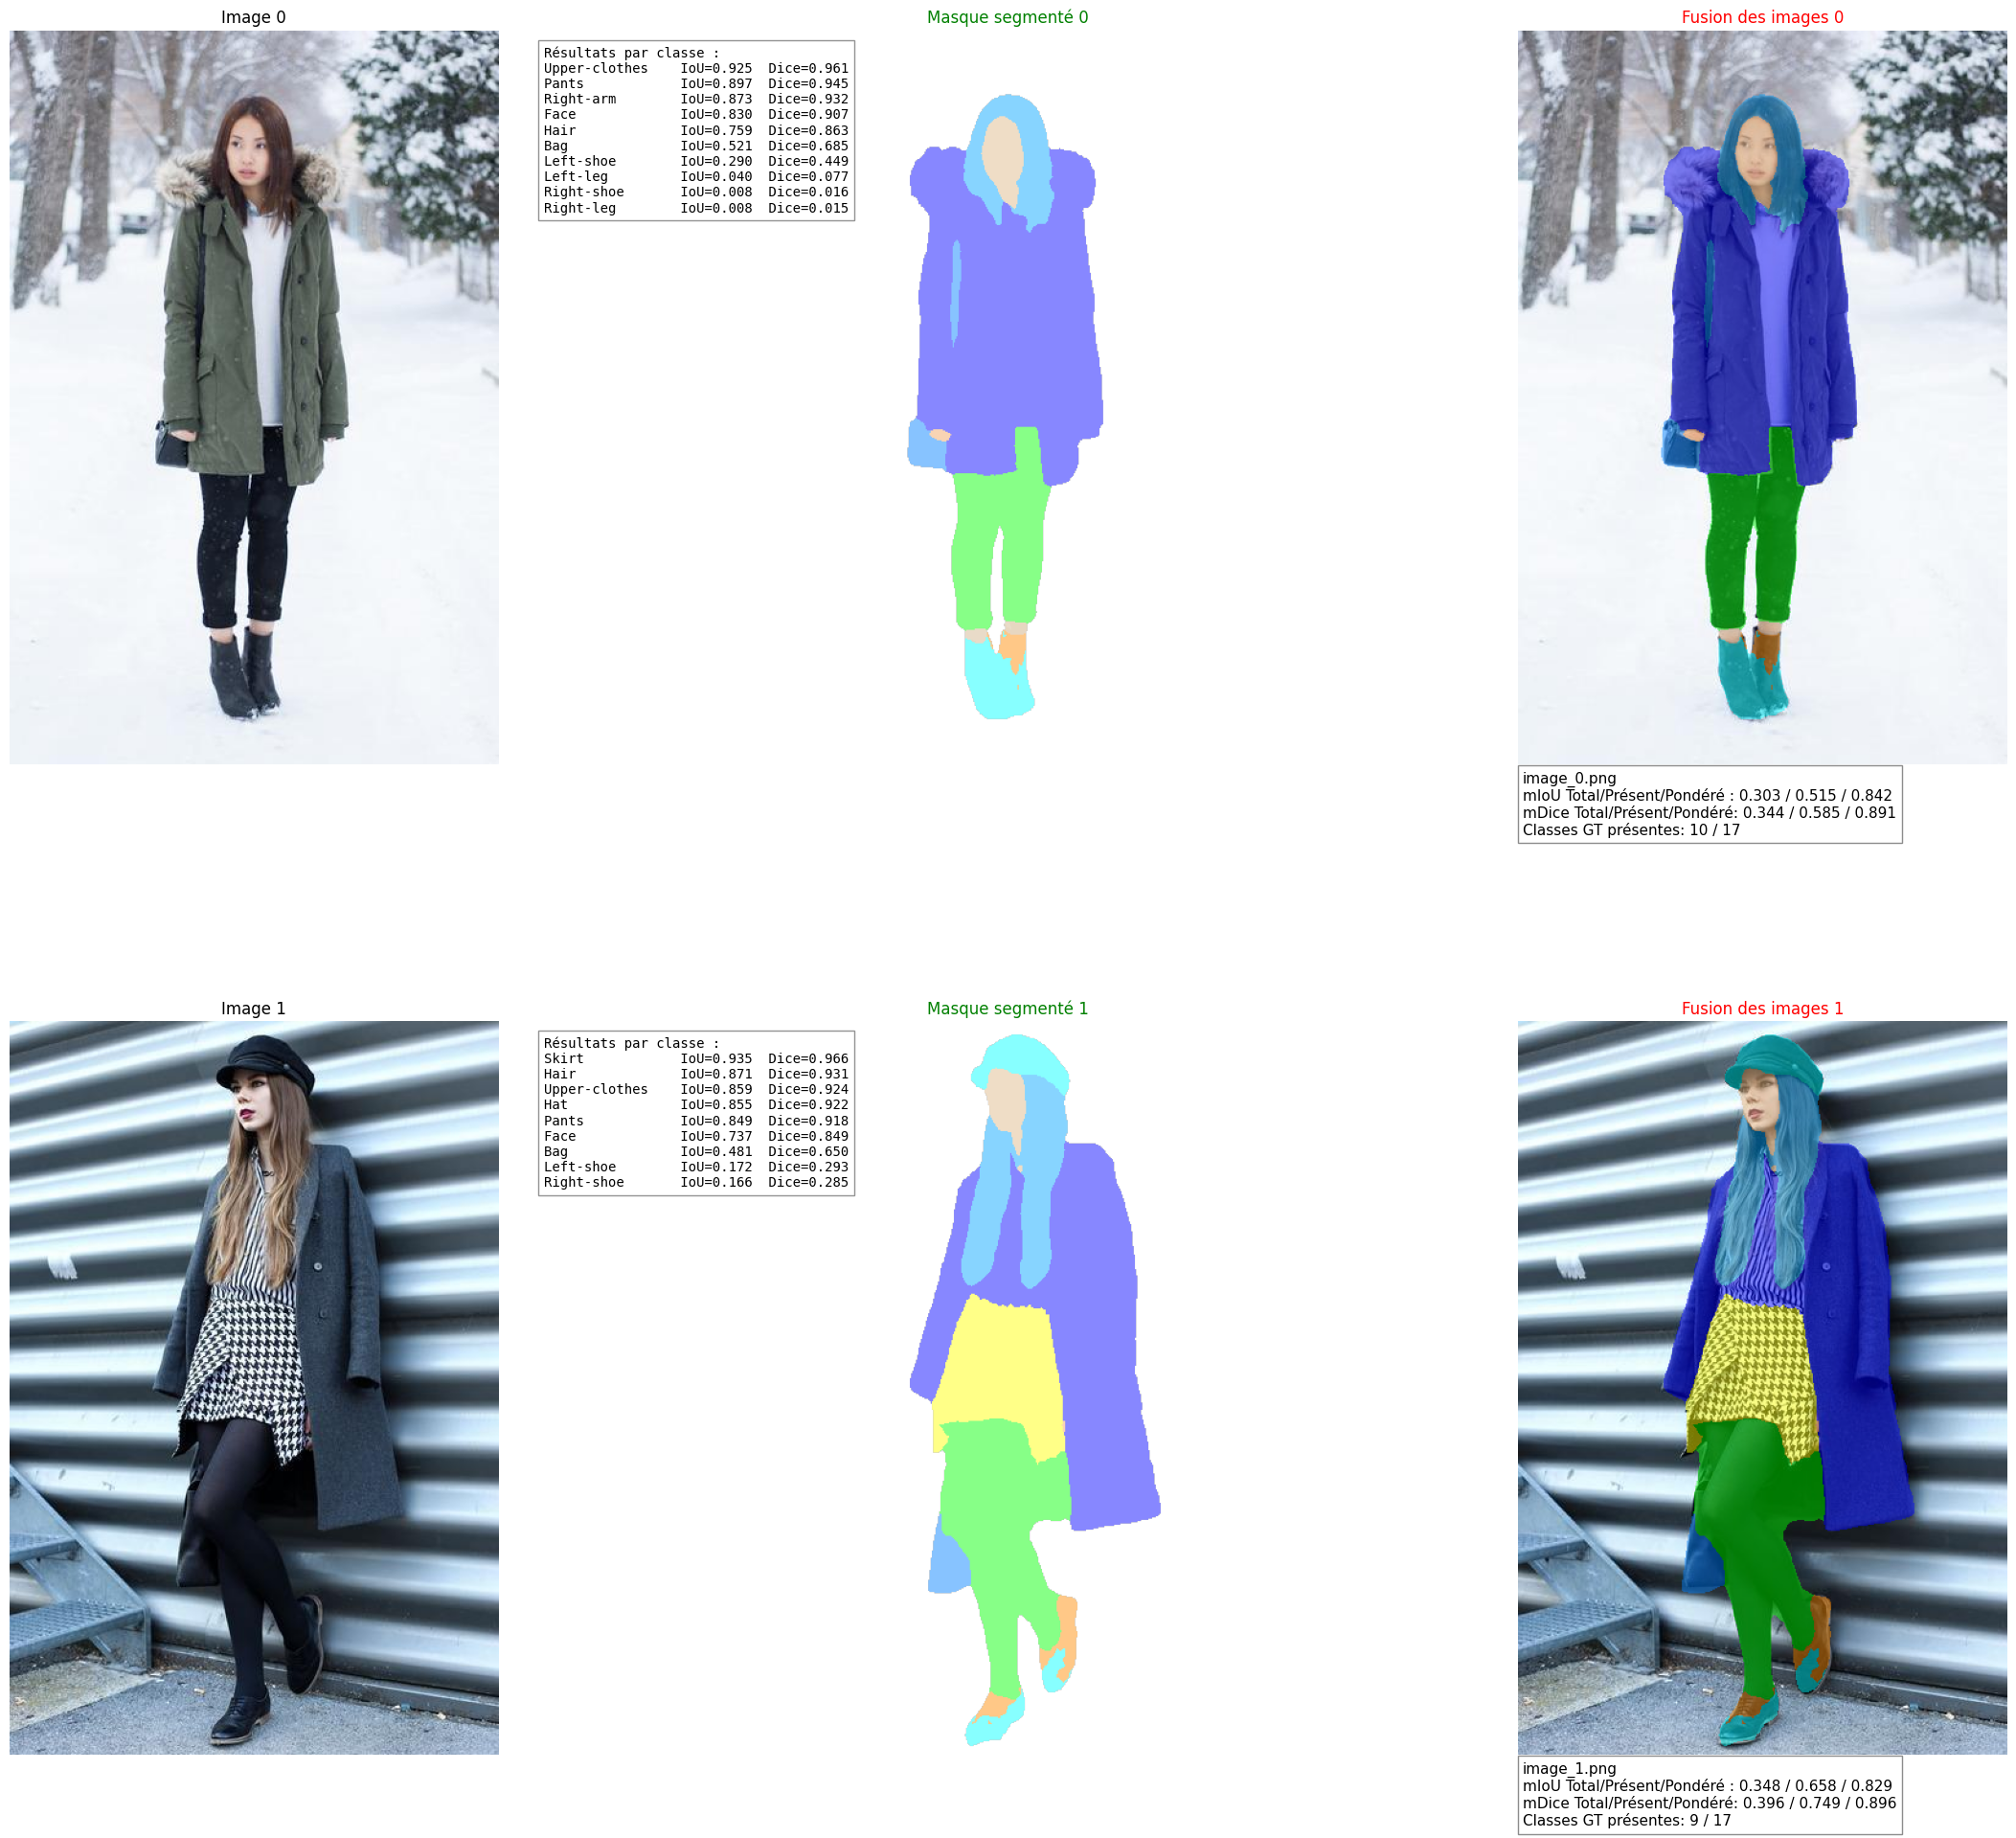

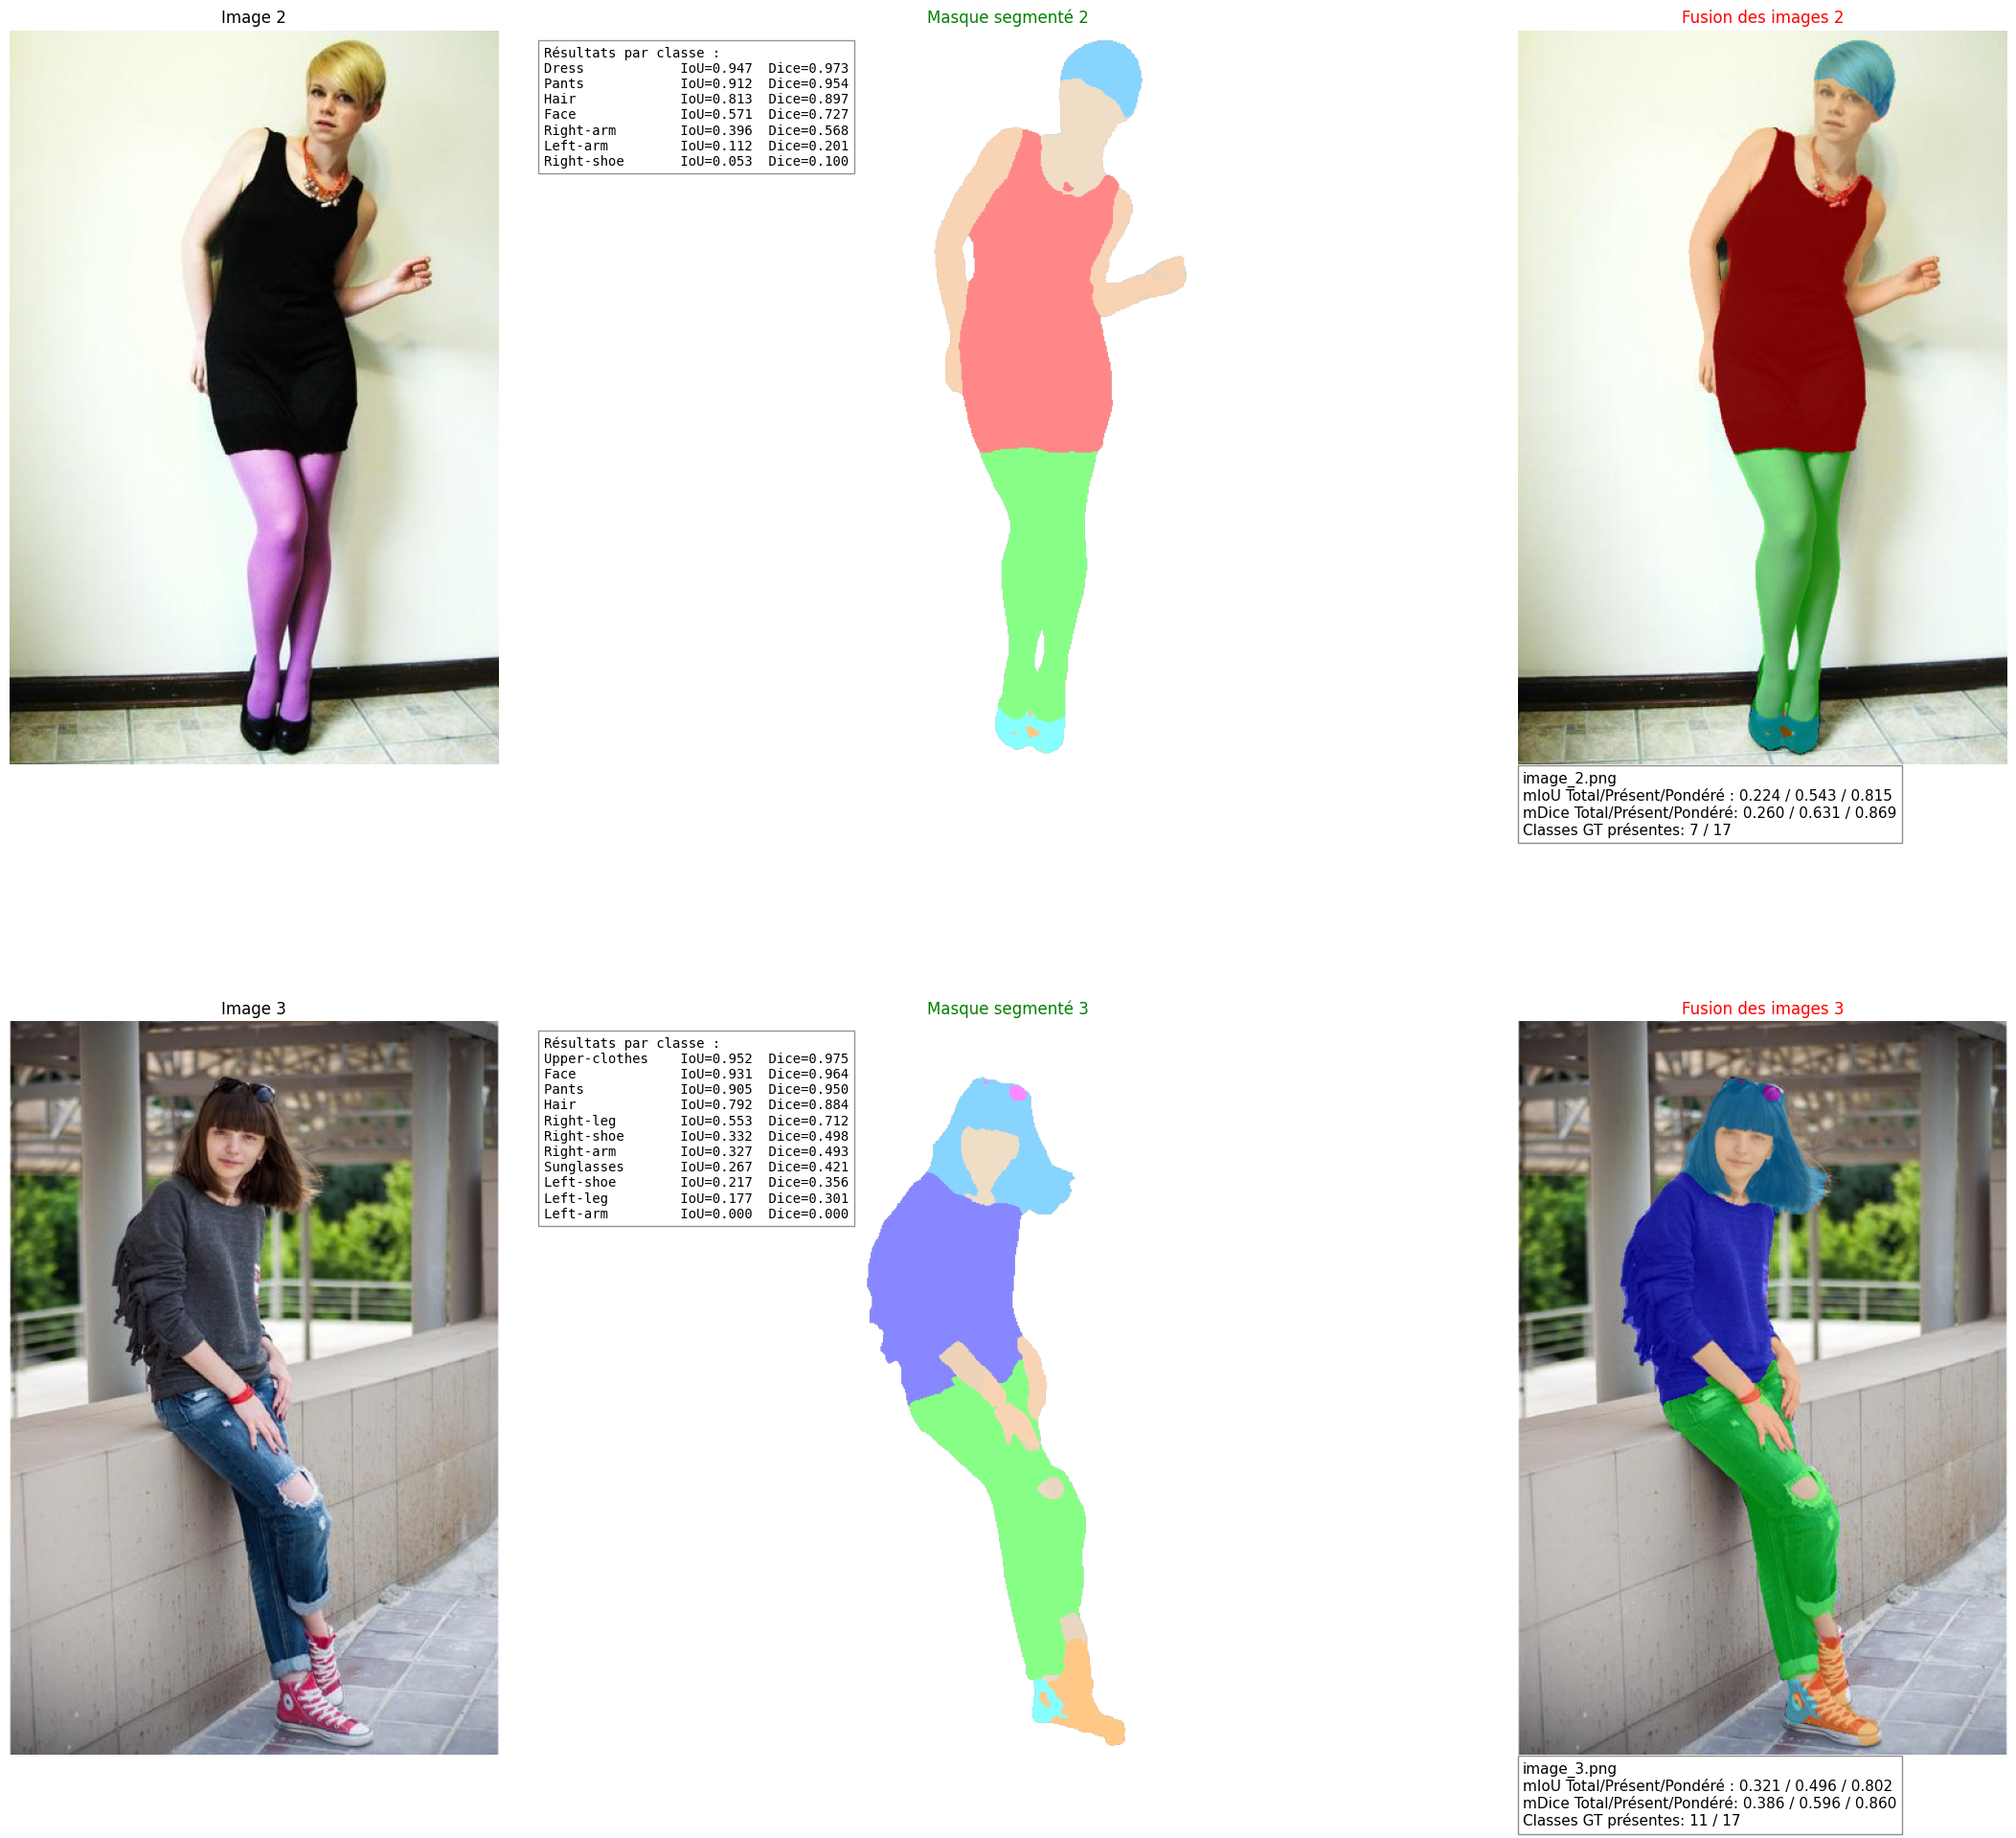

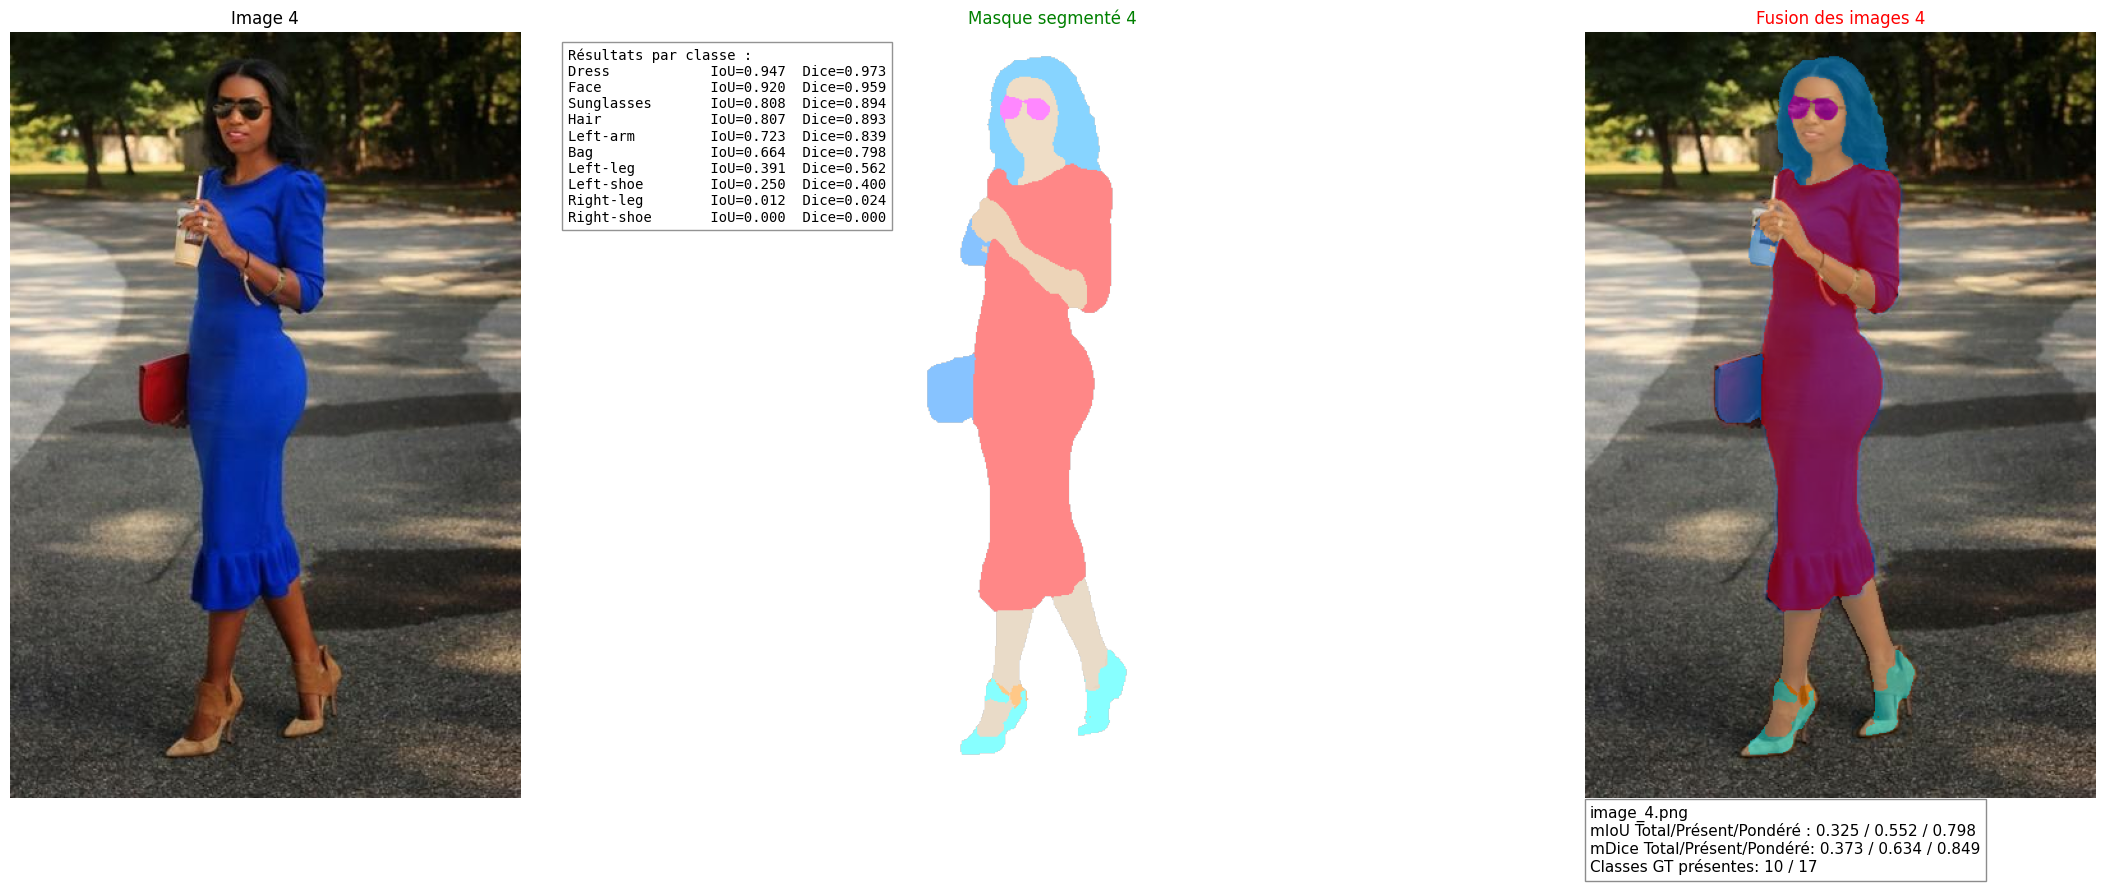

In [28]:
def display_segmented_images_batch(original_image_paths, segmentation_masks, dataframe_resultats, masque_segmentation="RGBA"):

    nombre_lignes = len(original_image_paths)
    nombre_colonnes = 3

    for ligne_en_cours in range(0,nombre_lignes,2) :
        
        ### Affiche les images originales et leurs masques segmentés.
        nombre_lignes_affichee = 2
        
        ### je definis l'organisation de mes images
        plt.figure(figsize=(nombre_colonnes * 10, nombre_lignes_affichee * 10))
        plt.subplots_adjust(top=0.95, bottom=0.05, hspace=0.35, wspace=0.05)

        for ligne_affichee in range(nombre_lignes_affichee) :

            # IMAGE DEPART
            plt.subplot(nombre_lignes_affichee, nombre_colonnes, ligne_affichee * 3 + 1)  # position du sous-graphe
            image_affichee = Image.open(original_image_paths[ligne_en_cours])
            plt.imshow(image_affichee)

            plt.title(f"Image {ligne_en_cours}")
            plt.axis("off") #retire le quadrillage

            # MASQUE COULEUR ou NUANCE DE GRIS
            ax3 = plt.subplot(nombre_lignes_affichee, nombre_colonnes, ligne_affichee * 3 + 2)
            mask_affiche = segmentation_masks[ligne_en_cours]
            
            if mask_affiche is not None:
                # Affiche le mask
                if masque_segmentation.upper() == "RGBA" :
                    plt.imshow(mask_affiche)
                else :
                    plt.imshow(mask_affiche,cmap="gray")
                    
                plt.title(f"Masque segmenté {ligne_en_cours}",color="green")
            else:
                plt.text(0.5, 0.5, "Aucun masque", ha="center", va="center", color="red")
                plt.title("Erreur / Manquant", color="red")
            
            plt.axis("off")

            #### FUSION IMAGE + MASQUE (SI NUANCES DE GRIS MASQUE = NUANCE DE ROUGE SUR LA FUSION)
            if mask_affiche is not None:
                ax4 = plt.subplot(nombre_lignes_affichee, nombre_colonnes, ligne_affichee * 3 + 3)
                
                if masque_segmentation.upper() == "RGBA" :
                    # convertion dans le meme format pour la fusion
                    image_RGBA = image_affichee.convert("RGBA")
                    mask_RGBA = mask_affiche.convert("RGBA")

                    # Verification des tailles des images et des mask
                    if mask_RGBA.size != image_RGBA.size:
                        mask_RGBA= mask_RGBA.resize(image_RGBA.size, resample=Image.NEAREST)

                    # la taille est identique donc fusion
                    fusion_images = Image.alpha_composite(image_RGBA, mask_RGBA)
                
                else :
                    image_RGBA = image_affichee.convert("RGBA")
                    mask_L =  mask_affiche.convert("L").resize(image_RGBA.size, Image.NEAREST)
                    
                    #Échelle le masque: 0 -> 0 (transparent), >0 -> opacité fixe (ex: 120/255)
                    OPACITE = 120  # ajuste entre 0 et 255
                    mask_alpha = mask_L.point(lambda p: OPACITE if p > 0 else 0)

                    #Je Crée un masque en rouge transparent
                    overlay = Image.new("RGBA", image_RGBA.size, (255, 0, 0, 0))  # rouge transparent
                    #j'y applique mon mask
                    overlay.putalpha(mask_alpha)  # masque devient alpha

                    # Fusion finale
                    fusion_images = Image.alpha_composite(image_RGBA, overlay)

                # Affichage fusion
                plt.imshow(fusion_images)
                plt.title(f"Fusion des images {ligne_en_cours}",color="red")

            else :

                plt.text(0.5, 0.5, "Pas de fusion", ha="center", va="center", color="red")
                plt.title("Erreur / Manquant", color="red")

            plt.axis("off")
            ## FIN FUSION

            ## CREATION LEGENDES
            nom_image= os.path.basename(original_image_paths[ligne_en_cours])
            dataframe_img = dataframe_resultats[dataframe_resultats["Nom_Image"] == nom_image]
                        
            if not dataframe_img.empty:
                
                ## LEGENDE RESULTATS PAR CLASSE, SUPPORT PRESENT SUR L'IMAGE DE DEPART
                df_sorted = dataframe_img.sort_values("IoU", ascending=False)
                lignes = ["Résultats par classe :"]

                for _, row in df_sorted.iterrows():
                    if row["Support"] > 0:
                        class_id = int(row["Classe_vetement"])
                        class_name = CLASS_NAMES.get(class_id, f"Class {class_id}")
                        lignes.append(f"{class_name:<15}  IoU={row['IoU']:.3f}  Dice={row['Dice']:.3f}")
                        txt_classes = "\n".join(lignes)

                ax3.text(
                    -0.45, 0.98, txt_classes,
                    transform=ax3.transAxes,
                    va="top", ha="left",
                    fontsize=10,
                    family="monospace",
                    bbox=dict(facecolor="white", alpha=0.85, edgecolor="gray")
                    )
                
                ## LEGENDE RESULTATS MOYENNES
                iou  = dataframe_img["IoU"].to_numpy(dtype=float)
                dice = dataframe_img["Dice"].to_numpy(dtype=float)
                sup  = dataframe_img["Support"].to_numpy(dtype=float)

                mIoU_tot = moyenne_total(iou)
                mIoU_pres = moyenne_presente(iou, sup)
                mIoU_pond = moyenne_ponderee(iou, sup)
                mDice_tot = moyenne_total(dice)
                mDice_pres = moyenne_presente(dice, sup)
                mDice_pond = moyenne_ponderee(dice, sup)

                txt = (
                    f"{nom_image}\n"
                    f"mIoU Total/Présent/Pondéré : {mIoU_tot:.3f} / {mIoU_pres:.3f} / {mIoU_pond:.3f}\n"
                    f"mDice Total/Présent/Pondéré: {mDice_tot:.3f} / {mDice_pres:.3f} / {mDice_pond:.3f}\n"
                    f"Classes GT présentes: {(sup>0).sum()} / {len(sup)}"
                )

                ax4.text(
                    0.01,
                    -0.1,  txt,
                    transform=ax4.transAxes,
                    va="bottom", ha="left",
                    fontsize=11,
                    bbox=dict(facecolor="white", alpha=0.9, edgecolor="gray")
                    )     
            
            ## COMPTEUR MANUEL POUR AFFICHAGE DES IMAGES EN 2 LIGNES
            ligne_en_cours += 1
            if ligne_en_cours > len(original_image_paths)-1 :
                break
        ## AFFICHAGE 2 LIGNES DE 3 IMAGES AVEC LEGENDES
        plt.subplots_adjust()
        plt.show()

    # Args:
    #     original_image_paths (list): Liste des chemins des images originales.
    #     segmentation_masks (list): Liste des masques segmentés (NumPy arrays).
        
if batch_seg_results:
    display_segmented_images_batch(image_paths, batch_seg_results, Resultats, masque_segmentation="RGBA") ## ici gray ou RGBA (par defaut)
else:
    print("Aucun résultat de segmentation à afficher.")
    

## Conclusion et Prochaines Étapes

Félicitations ! Vous avez appris à :
- Configurer les appels à l'API d'inférence Hugging Face.
- Envoyer des images pour la segmentation.
- Interpréter les résultats (avec l'aide des fonctions fournies).
- Visualiser les segmentations.

Pistes d'amélioration ou d'exploration :
- **Gestion d'erreurs plus fine** : Implémenter des tentatives multiples (retry) en cas d'échec de l'API (par exemple, si le modèle est en cours de chargement).
- **Appels asynchrones** : Pour un grand nombre d'images, des appels asynchrones (avec `asyncio` et `aiohttp`) seraient beaucoup plus rapides.
- **Autres modèles** : Explorer d'autres modèles de segmentation ou d'autres tâches sur Hugging Face Hub.

N'hésitez pas à modifier le code, à tester avec vos propres images et à explorer davantage !

**_Note_** : Si vous aimez ce modèle, n'hésitez pas à le [télécharger](https://huggingface.co/sayeed99/segformer_b3_clothes) et jouer avec directement sur votre machine !

## Conclusion et Prochaines Étapes

Félicitations ! Vous avez appris à :
- Configurer les appels à l'API d'inférence Hugging Face.
- Envoyer des images pour la segmentation.
- Interpréter les résultats (avec l'aide des fonctions fournies).
- Visualiser les segmentations.

Pistes d'amélioration ou d'exploration :
- **Gestion d'erreurs plus fine** : Implémenter des tentatives multiples (retry) en cas d'échec de l'API (par exemple, si le modèle est en cours de chargement).
- **Appels asynchrones** : Pour un grand nombre d'images, des appels asynchrones (avec `asyncio` et `aiohttp`) seraient beaucoup plus rapides.
- **Autres modèles** : Explorer d'autres modèles de segmentation ou d'autres tâches sur Hugging Face Hub.

N'hésitez pas à modifier le code, à tester avec vos propres images et à explorer davantage !

**_Note_** : Si vous aimez ce modèle, n'hésitez pas à le [télécharger](https://huggingface.co/sayeed99/segformer_b3_clothes) et jouer avec directement sur votre machine !

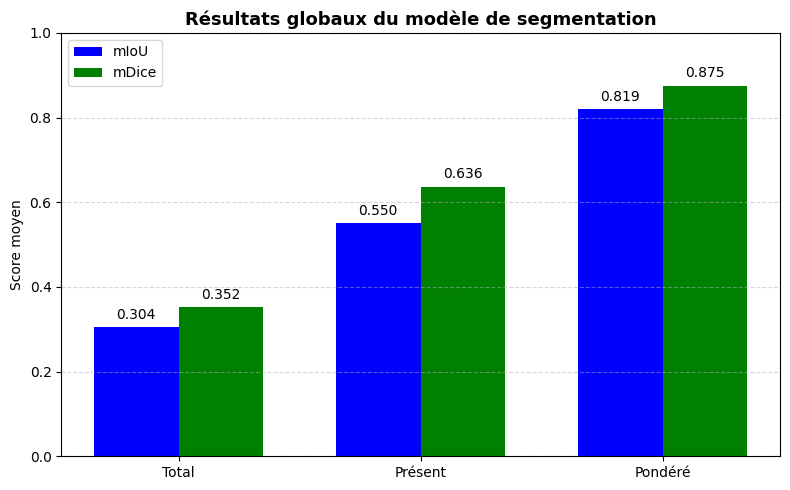

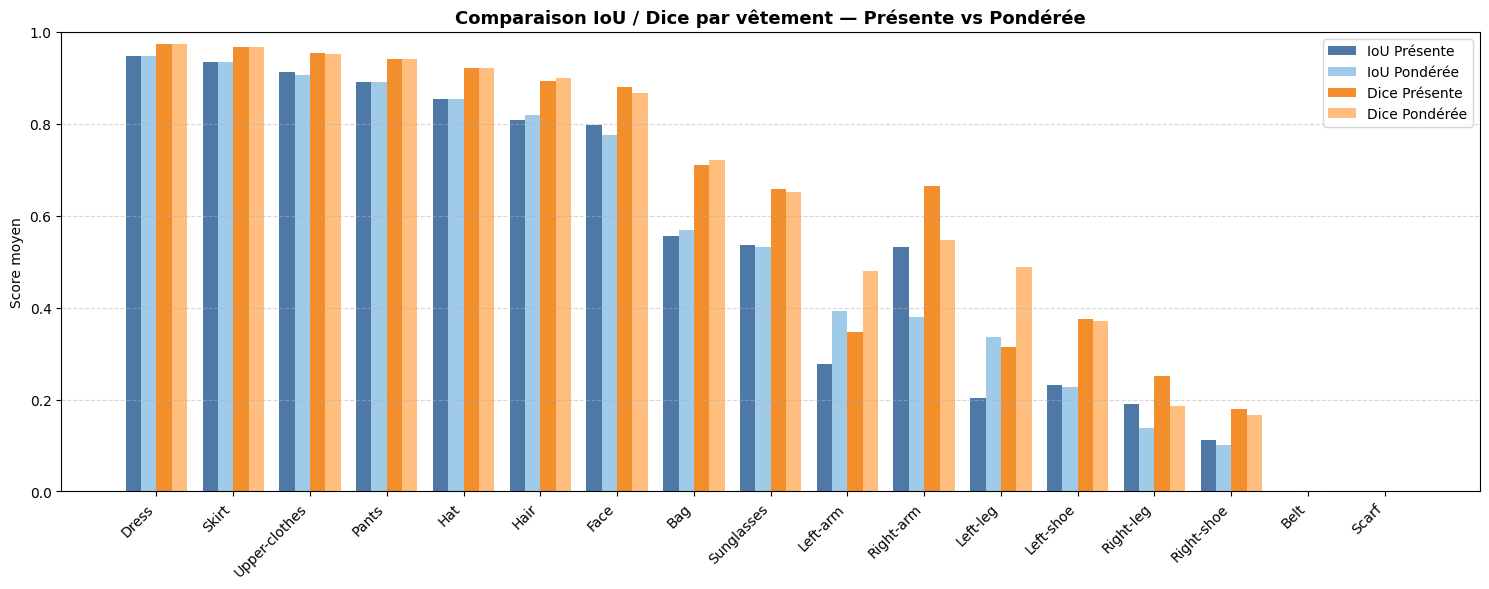

 Classe_vetement        Classe  Support_total  IoU_Presente  IoU_Ponderee  Dice_Presente  Dice_Ponderee
               7         Dress        49929.0         0.947         0.947          0.973          0.973
               5         Skirt        10040.0         0.935         0.935          0.966          0.966
               4 Upper-clothes        77319.0         0.912         0.907          0.953          0.951
               6         Pants        46835.0         0.891         0.890          0.942          0.942
               1           Hat         2132.0         0.855         0.855          0.922          0.922
               2          Hair        22527.0         0.808         0.819          0.894          0.900
              11          Face        11094.0         0.798         0.777          0.881          0.866
              16           Bag         4320.0         0.556         0.570          0.711          0.722
               3    Sunglasses         1070.0         0.537     

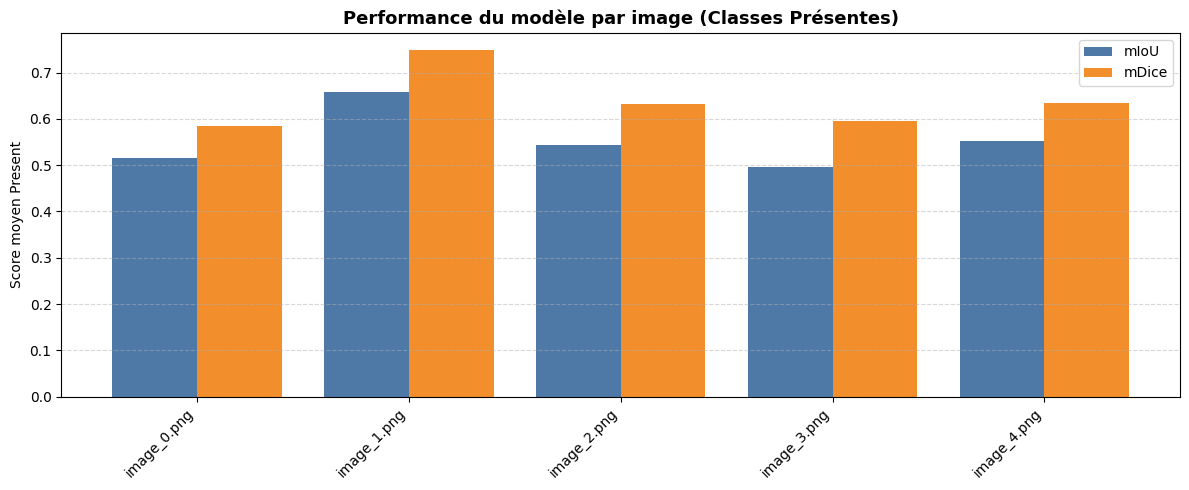

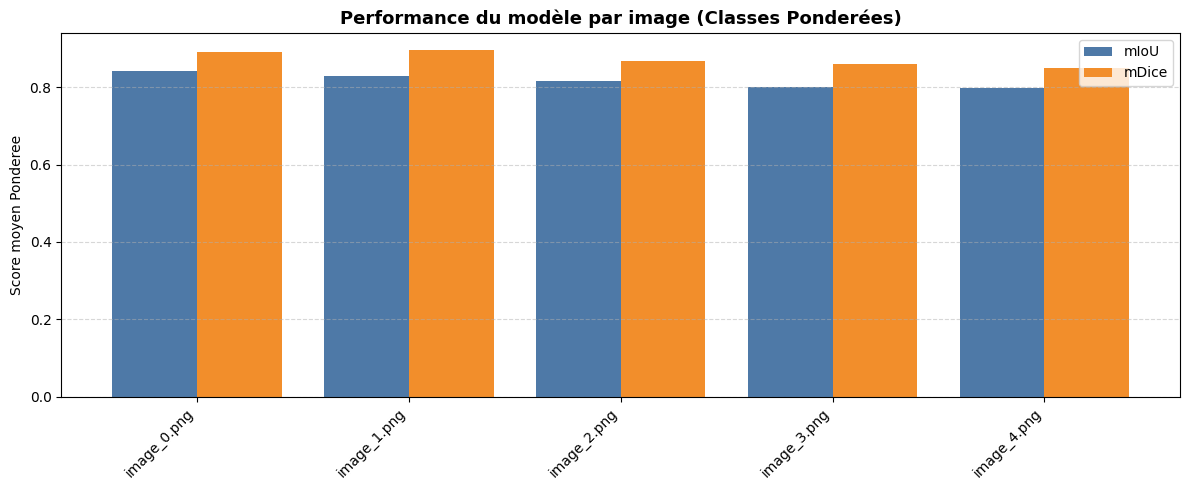

In [ ]:
# Évaluation du modèle de segmentation SegFormer_B3_Clothes

## 1. Objectif et contexte
#L’objectif de ce projet est d’évaluer les performances du modèle SegFormer_B3_Clothes 
# pour la segmentation sémantique de vêtements sur des images humaines.
#Cette évaluation vise à mesurer la capacité du modèle à identifier et distinguer correctement différentes catégories vestimentaires
# (chapeau, pantalon, robe, etc.) à l’aide de métriques quantitatives telles que l’IoU (Intersection over Union) 
# et le Dice Score (de similarité entre le masque prédit et le masque réel 2Inter/(zone1 + Zone2)).

## 2. Résultats globaux
df = Resultats.copy()

df["IoU"] = df["IoU"].astype(float)
df["Dice"] = df["Dice"].astype(float)
df["Support"] = df["Support"].astype(float)

mIoU_all      = moyenne_total(df["IoU"])
mIoU_present  = moyenne_presente(df["IoU"], df["Support"])
mIoU_weighted = moyenne_ponderee(df["IoU"], df["Support"])
mDice_all      = moyenne_total(df["Dice"])
mDice_present  = moyenne_presente(df["Dice"], df["Support"])
mDice_weighted = moyenne_ponderee(df["Dice"], df["Support"])

resume_mIoU_global = pd.DataFrame([{
    "mIoU_Total": mIoU_all, "mIoU_Presente": mIoU_present, "mIoU_Ponderee": mIoU_weighted,
    "nb_images": df["Nom_Image"].nunique(),
    "classes_presentes_moy": df.groupby("Nom_Image")["Support"].apply(lambda s: (s>0).sum()).mean()
}])

resume_Dice_global = pd.DataFrame([{
    "mDice_Total": mDice_all, "mDice_Presente": mDice_present, "mDice_Poderee": mDice_weighted, 
    "nb_images": df["Nom_Image"].nunique(),
    "classes_presentes_moy": df.groupby("Nom_Image")["Support"].apply(lambda s: (s>0).sum()).mean()
}])

### Données globales
categories = ["Total", "Présent", "Pondéré"]
iou_scores = [mIoU_all, mIoU_present, mIoU_weighted]
dice_scores = [mDice_all, mDice_present, mDice_weighted]

x = np.arange(len(categories))
width = 0.35

plt.figure(figsize=(8,5))
plt.bar(x - width/2, iou_scores, width, label='mIoU', color="blue")
plt.bar(x + width/2, dice_scores, width, label='mDice', color="green")

plt.xticks(x, categories)
plt.ylabel("Score moyen")
plt.ylim(0, 1.0)
plt.title("Résultats globaux du modèle de segmentation", fontsize=13, weight="bold")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Ajout des valeurs sur les barres
for i in range(len(categories)):
    plt.text(x[i]-width/2, iou_scores[i]+0.02, f"{iou_scores[i]:.3f}", ha='center', fontsize=10)
    plt.text(x[i]+width/2, dice_scores[i]+0.02, f"{dice_scores[i]:.3f}", ha='center', fontsize=10)

plt.tight_layout()
plt.show()

df = Resultats.copy()

df["IoU"] = df["IoU"].astype(float)
df["Dice"] = df["Dice"].astype(float)
df["Support"] = df["Support"].astype(float)

df_cls = df[df["Classe_vetement"] != 0]

rows = []

for classe, g in df_cls.groupby("Classe_vetement"):
    iou = g["IoU"].to_numpy()
    dice = g["Dice"].to_numpy()
    sup = g["Support"].to_numpy()

    # Application de TES fonctions
    iou_pres = moyenne_presente(iou, sup)
    iou_pond = moyenne_ponderee(iou, sup)
    dice_pres = moyenne_presente(dice, sup)
    dice_pond = moyenne_ponderee(dice, sup)

    rows.append({
        "Classe_vetement": classe,
        "Classe": CLASS_NAMES.get(classe, f"Classe {classe}"),
        "Support_total": sup.sum(),
        "IoU_Presente": iou_pres,
        "IoU_Ponderee": iou_pond,
        "Dice_Presente": dice_pres,
        "Dice_Ponderee": dice_pond
    })

# --- Résumé en DataFrame ---
df_moy = pd.DataFrame(rows).sort_values("IoU_Ponderee", ascending=False)

# --- Graphique à 4 barres par classe ---
x = np.arange(len(df_moy))
bar_width = 0.2

plt.figure(figsize=(15, 6))
plt.bar(x - 1.5*bar_width, df_moy["IoU_Presente"], width=bar_width, label="IoU Présente", color="#4e79a7")
plt.bar(x - 0.5*bar_width, df_moy["IoU_Ponderee"], width=bar_width, label="IoU Pondérée", color="#a0cbe8")
plt.bar(x + 0.5*bar_width, df_moy["Dice_Presente"], width=bar_width, label="Dice Présente", color="#f28e2b")
plt.bar(x + 1.5*bar_width, df_moy["Dice_Ponderee"], width=bar_width, label="Dice Pondérée", color="#ffbe7d")

plt.xticks(x, df_moy["Classe"], rotation=45, ha="right")
plt.ylabel("Score moyen")
plt.title("Comparaison IoU / Dice par vêtement — Présente vs Pondérée", fontsize=13, weight="bold")
plt.ylim(0, 1.0)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# --- Tableau récapitulatif ---
print(df_moy.round(3).to_string(index=False))

## 5. Résultats par Images
df=Resultats.copy()
#print(Resultats.round(3).to_string(index=False))

df["IoU"] = df["IoU"].astype(float)
df["Dice"] = df["Dice"].astype(float)
df["Support"] = df["Support"].astype(float)

rows = []

for img, g in df.groupby("Nom_Image", sort=False):
    iou = g["IoU"].to_numpy(dtype=float)
    dice = g["Dice"].to_numpy(dtype=float)
    sup = g["Support"].to_numpy(dtype=float)
    
    g_pres = g[g["Support"] > 0]
    if g_pres.empty:
        continue

    iou = g_pres["IoU"].to_numpy()
    dice = g_pres["Dice"].to_numpy()
    sup = g_pres["Support"].to_numpy()
    
    mIoU_pres = moyenne_presente(iou, sup)
    mDice_pres = moyenne_presente(dice, sup)
    mIoU_pond = moyenne_ponderee(iou, sup)
    mDice_pond = moyenne_ponderee(dice, sup)

    rows.append({
        "Nom_Image": img,
        "mIoU_Presente": mIoU_pres,
        "mDice_Presente": mDice_pres,
        "mIoU_Ponderee": mIoU_pond,
        "mDice_Ponderee": mDice_pond,
        "classes_GT": int((sup > 0).sum())
    })

#df_img = pd.DataFrame(rows).sort_values("mIoU_Presente", ascending=False)
# print(df_img.round(3).to_string(index=False))
df_img = pd.DataFrame(rows)

x = np.arange(len(df_img))
bar_width = 0.4

plt.figure(figsize=(12, 5))
plt.bar(x - bar_width/2, df_img["mIoU_Presente"], width=bar_width, label="mIoU", color="#4e79a7")
plt.bar(x + bar_width/2, df_img["mDice_Presente"], width=bar_width, label="mDice", color="#f28e2b")

plt.xticks(x, df_img["Nom_Image"], rotation=45, ha="right")
plt.ylabel("Score moyen Present")
plt.title("Performance du modèle par image (Classes Présentes)", fontsize=13, weight="bold")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

x = np.arange(len(df_img))
bar_width = 0.4

plt.figure(figsize=(12, 5))
plt.bar(x - bar_width/2, df_img["mIoU_Ponderee"], width=bar_width, label="mIoU", color="#4e79a7")
plt.bar(x + bar_width/2, df_img["mDice_Ponderee"], width=bar_width, label="mDice", color="#f28e2b")

plt.xticks(x, df_img["Nom_Image"], rotation=45, ha="right")
plt.ylabel("Score moyen Ponderee")
plt.title("Performance du modèle par image (Classes Ponderées)", fontsize=13, weight="bold")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 5. Analyse qualitative
# - Erreurs sur les classes "shoes", “hat” et “scarf” → objets petits.
# - Très bonnes performances sur "dress", "skirt", “upper-clothes” et “pants”.

## 6. Conclusion
# ...
